**ACTIVITY 1**

In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# AND gate inputs and outputs
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])  # AND gate outputs

In [2]:
# Initialize random weights and bias
weights = np.random.rand(2) * 0.1
bias = np.random.rand(1)[0] * 0.1

# Define step activation function
def step_function(z):
    return 1 if z >= 0 else 0

# Set learning rate and epochs
learning_rate = 0.1
epochs = 20

# Train the perceptron
for epoch in range(epochs):
    for x, y_true in zip(X_and, y_and):

        # Calculate weighted sum
        z = np.dot(x, weights) + bias

        # Make prediction
        prediction = step_function(z)

        # Calculate error
        error = y_true - prediction

        # Update weights
        weights = weights + learning_rate * error * x

        # Update bias
        bias = bias + learning_rate * error

# Test the perceptron
print("AND Gate Predictions:")
for x in X_and:
    z = np.dot(x, weights) + bias
    prediction = step_function(z)
    print(x, "->", prediction)

AND Gate Predictions:
[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


**ACTIVITY 2**

In [3]:
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [4]:
# Sample data for shapes
# Features: NumCorners, AspectRatio
# Target: 0 = Square, 1 = Circle

X_shapes = np.array([
    [4, 1.0],
    [4, 1.05],
    [4, 0.95],  # Squares
    [0, 1.0],
    [0, 1.1],
    [0, 0.9],   # Circles
    [4, 0.5],
    [0, 2.0]    # Some noisy or mislabeled points
])

y_shapes = np.array([0, 0, 0, 1, 1, 1, 0, 1])

In [5]:
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_shapes, y_shapes, test_size=0.3, random_state=42
)

print("Shape Classification Data (X_train_s):\n", X_train_s)
print("\nShape Target (y_train_s):\n", y_train_s)

Shape Classification Data (X_train_s):
 [[0.   2.  ]
 [4.   0.95]
 [0.   1.1 ]
 [0.   1.  ]
 [4.   0.5 ]]

Shape Target (y_train_s):
 [1 0 1 1 0]


In [6]:
# Initialize the MLP classifier
model = MLPClassifier(
    hidden_layer_sizes=(5,),
    max_iter=500,
    random_state=42,
    solver='adam'
)

# Train the model
model.fit(X_train_s, y_train_s)

# Make predictions
y_pred_s = model.predict(X_test_s)

# Calculate accuracy
accuracy = accuracy_score(y_test_s, y_pred_s)

print("MLP Classification Accuracy:", accuracy)
print("MLP Classification Accuracy (%):", accuracy * 100)

MLP Classification Accuracy: 1.0
MLP Classification Accuracy (%): 100.0


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


**ACTIVITY 3**

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


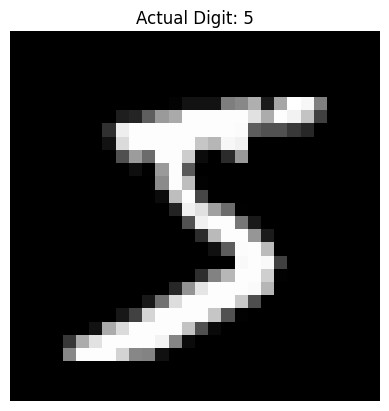

In [8]:

plt.imshow(X_train[0], cmap='gray')
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis('off')
plt.show()


In [9]:

# Flatten each 28x28 image into 784 values
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Convert digit labels into one-hot encoded vectors
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Processed training data:", X_train.shape)
print("Encoded labels:", y_train_cat.shape)


Processed training data: (60000, 784)
Encoded labels: (60000, 10)


In [10]:

model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9034 - loss: 0.3434 - val_accuracy: 0.9633 - val_loss: 0.1353
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9578 - loss: 0.1433 - val_accuracy: 0.9657 - val_loss: 0.1182
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9702 - loss: 0.1008 - val_accuracy: 0.9733 - val_loss: 0.0954
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9775 - loss: 0.0770 - val_accuracy: 0.9752 - val_loss: 0.0849
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9820 - loss: 0.0601 - val_accuracy: 0.9760 - val_loss: 0.0817


In [11]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test_cat, verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)


Test Loss: 0.07370982319116592
Test Accuracy: 0.9775999784469604
Test Accuracy (%): 97.75999784469604


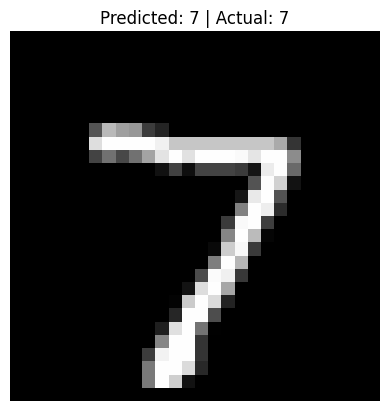

In [12]:

index = 0

prediction = model.predict(X_test[index:index+1], verbose=0)
predicted_digit = np.argmax(prediction)

plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test[index]}")
plt.axis('off')
plt.show()


**ACTIVITY 4**

In [13]:

import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

# Load the same dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Use a smaller training subset to make comparison faster
X_train = X_train[:12000]
y_train = y_train[:12000]

# Flatten images
X_train = X_train.reshape(-1, 784).astype('float32') / 255.0
X_test = X_test.reshape(-1, 784).astype('float32') / 255.0

# One-hot encode labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (12000, 784)
Testing data: (10000, 784)


In [14]:

activation_functions = ['sigmoid', 'tanh', 'relu']

results = []
histories = {}
models = {}

for activation in activation_functions:

    print("\nTraining with activation:", activation)

    model = Sequential([
        Input(shape=(784,)),
        Dense(64, activation=activation),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train_cat,
        epochs=10,
        batch_size=128,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=0
    )

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test_cat, verbose=0
    )

    epochs_used = len(history.history['loss'])

    results.append({
        'Activation': activation,
        'Epochs': epochs_used,
        'Training Time (seconds)': round(training_time, 2),
        'Test Accuracy (%)': round(test_accuracy * 100, 2),
        'Test Loss': round(test_loss, 4)
    })

    histories[activation] = history.history
    models[activation] = model

    print("Epochs:", epochs_used)
    print("Training time:", round(training_time, 2), "seconds")
    print("Test accuracy:", round(test_accuracy * 100, 2), "%")



Training with activation: sigmoid
Epochs: 10
Training time: 7.08 seconds
Test accuracy: 92.0 %

Training with activation: tanh
Epochs: 10
Training time: 6.89 seconds
Test accuracy: 93.36 %

Training with activation: relu
Epochs: 10
Training time: 6.42 seconds
Test accuracy: 93.76 %


In [15]:

results_df = pd.DataFrame(results)

print("Activation Function Comparison:")
print(results_df.to_string(index=False))


Activation Function Comparison:
Activation  Epochs  Training Time (seconds)  Test Accuracy (%)  Test Loss
   sigmoid      10                     7.08              92.00     0.2938
      tanh      10                     6.89              93.36     0.2242
      relu      10                     6.42              93.76     0.2069


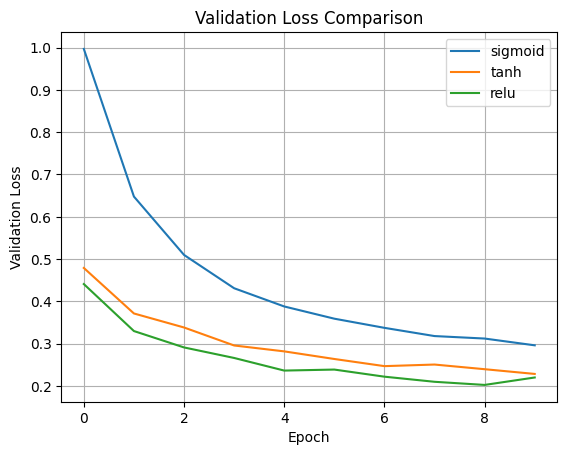

In [16]:

for activation in activation_functions:
    plt.plot(
        histories[activation]['val_loss'],
        label=activation
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


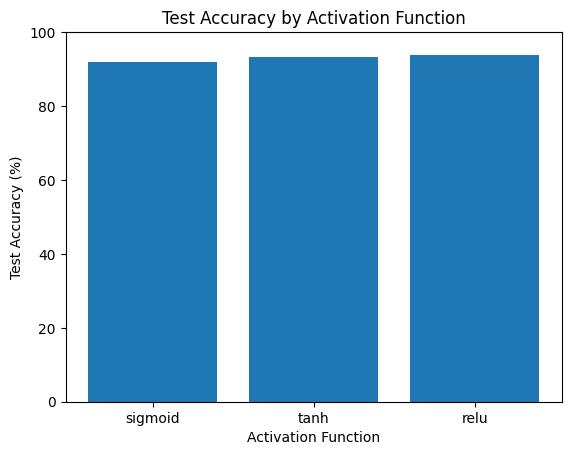

In [17]:

plt.bar(
    results_df['Activation'],
    results_df['Test Accuracy (%)']
)

plt.title("Test Accuracy by Activation Function")
plt.xlabel("Activation Function")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.show()
